# 11장. 제조 이미지와 웨이퍼맵 전처리

「AI로 만드는 제조공정 품질관리 따라하기」 11장 실습 Notebook입니다. CPU 런타임으로 충분합니다.

WM-811K는 Kaggle에서 받습니다. Colab에서는 왼쪽 열쇠 아이콘(보안 비밀)에 `KAGGLE_API_TOKEN`을 등록하세요.
(Kaggle → Settings → API → Create New Token에서 발급)

In [1]:
import os
import sys
from pathlib import Path

if "google.colab" in sys.modules and not Path("src").exists():
    !git clone -q https://github.com/ady95/manufacturing-ai-tutorial.git
    %cd manufacturing-ai-tutorial/03-defect-inspection/wafermap
    !pip install -q -U kaggle
    from google.colab import userdata
    os.environ["KAGGLE_API_TOKEN"] = userdata.get("KAGGLE_API_TOKEN")

ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))
Path("results").mkdir(exist_ok=True)

In [2]:
import json
import time

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedShuffleSplit

from src.wafer_utils import (CLASSES, FEATURE_NAMES, SEED, classification_report_dict, dev_val_split, env_info,
                             handcrafted_features, load_raw, prepare, resize_map)

ENV = env_info()
print(ENV)

{'python': '3.12.9', 'numpy': '2.5.5', 'pandas': '3.1.1', 'sklearn': '1.9.1', 'opencv': '5.1.0', 'torch': '2.14.1+cu126', 'torchvision': '0.29.1+cu126', 'device': 'NVIDIA GeForce GTX 1080'}


## 11-3. WM-811K 데이터 구조 (원본)

In [3]:
t0 = time.perf_counter()
raw = load_raw()
print(f"읽기 {time.perf_counter() - t0:.1f}초 | {raw.shape} | {list(raw.columns)}")
labeled = raw[raw["label"].notna()]
print("라벨 있음:", len(labeled), "| 없음:", raw["label"].isna().sum())
counts = labeled["label"].value_counts()
print(counts)

읽기 7.7초 | (811457, 8) | ['waferMap', 'dieSize', 'lotName', 'waferIndex', 'trianTestLabel', 'failureType', 'label', 'split']
라벨 있음: 172950 | 없음: 638507
label
none         147431
Edge-Ring      9680
Edge-Loc       5189
Center         4294
Loc            3593
Scratch        1193
Random          866
Donut           555
Near-full       149
Name: count, dtype: int64


In [4]:
ct = pd.crosstab(labeled["label"], labeled["split"]).reindex(CLASSES)
ct_pct = (ct / ct.sum() * 100).round(2)
print(ct)
print(ct_pct)
print("Lot 수:", labeled.groupby("split")["lotName"].nunique().to_dict())
lot_num = labeled["lotName"].str.extract(r"(\d+)")[0].astype(int)
print("Lot 번호 범위:", lot_num.groupby(labeled["split"]).agg(["min", "max"]).to_dict("index"))
both = labeled.groupby("lotName")["split"].nunique()
print("Training·Test에 함께 있는 Lot:", int((both > 1).sum()))

split        Test  Training
label                      
Center        832      3462
Donut         146       409
Edge-Loc     2772      2417
Edge-Ring    1126      8554
Loc          1973      1620
Near-full      95        54
Random        257       609
Scratch       693       500
none       110701     36730
split       Test  Training
label                     
Center      0.70      6.37
Donut       0.12      0.75
Edge-Loc    2.34      4.45
Edge-Ring   0.95     15.74
Loc         1.66      2.98
Near-full   0.08      0.10
Random      0.22      1.12
Scratch     0.58      0.92
none       93.34     67.57
Lot 수: {'Test': 4953, 'Training': 5809}


Lot 번호 범위: {'Test': {'min': 40328, 'max': 47542}, 'Training': {'min': 1, 'max': 46729}}
Training·Test에 함께 있는 Lot: 0


### 유형별 예시 (원본 크기)

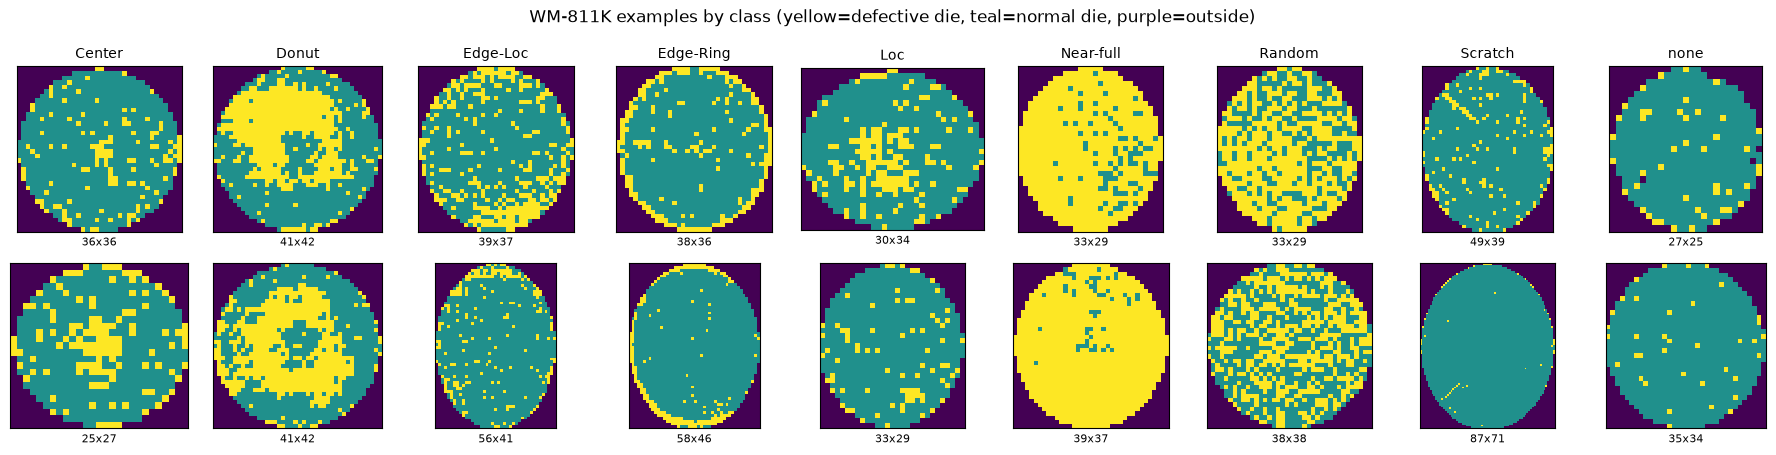

In [5]:
fig, axes = plt.subplots(2, 9, figsize=(18, 4.6))
rng = np.random.default_rng(SEED)
for j, c in enumerate(CLASSES):
    idx = rng.choice(np.flatnonzero(labeled["label"].to_numpy() == c), 2, replace=False)
    for i, k in enumerate(idx):
        m = labeled["waferMap"].iloc[k]
        axes[i, j].imshow(m, cmap="viridis", vmin=0, vmax=2, interpolation="nearest")
        axes[i, j].set_xticks([]); axes[i, j].set_yticks([])
        axes[i, j].set_xlabel(f"{m.shape[0]}x{m.shape[1]}", fontsize=8)
    axes[0, j].set_title(c, fontsize=10)
fig.suptitle("WM-811K examples by class (yellow=defective die, teal=normal die, purple=outside)")
plt.tight_layout()
plt.savefig("results/11_class_examples.png", dpi=110)
plt.show()

In [6]:
shapes = labeled["waferMap"].map(lambda m: m.shape)
size_by_class = (pd.DataFrame({"label": labeled["label"], "H": shapes.str[0], "W": shapes.str[1]})
                 .groupby("label")[["H", "W"]].median().reindex(CLASSES))
print("서로 다른 맵 크기:", shapes.nunique())
print(size_by_class)
del raw

서로 다른 맵 크기: 346
              H     W
label                
Center     25.0  27.0
Donut      41.0  42.0
Edge-Loc   36.0  34.0
Edge-Ring  53.0  52.0
Loc        35.0  34.0
Near-full  33.0  29.0
Random     35.0  38.0
Scratch    41.0  38.0
none       33.0  31.0


## 학습용 데이터 구성: 64×64 최근접 보간 캐시

In [7]:
t0 = time.perf_counter()
D = prepare()
print(f"준비 {time.perf_counter() - t0:.1f}초", {k: v.shape for k, v in D.items()})
maps, y = D["maps"], D["y"]
is_train, is_test = D["split"] == "Training", D["split"] == "Test"
tr, va = dev_val_split(D["lot_num"], is_train)
print("학습", tr.sum(), "| 검증", va.sum(), "| 평가", is_test.sum())
print("검증 Lot 번호 시작:", D["lot_num"][va].min())

준비 1.8초 {'maps': (172950, 64, 64), 'y': (172950,), 'split': (172950,), 'lot': (172950,), 'lot_num': (172950,), 'H': (172950,), 'W': (172950,), 'n_defect': (172950,), 'md5': (172950,)}
학습 43461 | 검증 10894 | 평가 118595
검증 Lot 번호 시작: 44930


### 같은 맵이 Training과 Test에 모두 있는가

In [8]:
train_md5 = set(D["md5"][is_train])
dup_test = is_test & np.isin(D["md5"], list(train_md5))
print("Training과 똑같은 Test 맵:", int(dup_test.sum()))
print(pd.Series(np.array(CLASSES)[y[dup_test]]).value_counts().to_dict())
g = pd.DataFrame({"md5": D["md5"], "y": y}).groupby("md5")["y"].nunique()
print("똑같은 맵인데 라벨이 다른 경우:", int((g > 1).sum()))

Training과 똑같은 Test 맵: 3158
{'none': 3057, 'Edge-Loc': 37, 'Loc': 21, 'Random': 14, 'Scratch': 11, 'Edge-Ring': 6, 'Center': 6, 'Near-full': 6}
똑같은 맵인데 라벨이 다른 경우: 14


### 지름길 확인: 맵 크기만으로 유형을 맞힐 수 있는가

In [9]:
size_feat = np.c_[D["H"], D["W"]]


def size_only(train_idx, test_idx):
    rf = RandomForestClassifier(300, min_samples_leaf=2, n_jobs=-1, random_state=SEED)
    rf.fit(size_feat[train_idx], y[train_idx])
    return classification_report_dict(y[test_idx], rf.predict(size_feat[test_idx]))


sss = StratifiedShuffleSplit(n_splits=1, test_size=0.3, random_state=SEED)
r_tr, r_te = next(sss.split(size_feat, y))
shortcut = {"무작위 분리": size_only(r_tr, r_te),
            "공식 분리": size_only(np.flatnonzero(is_train), np.flatnonzero(is_test))}
for k, v in shortcut.items():
    print(f"{k}: accuracy {v['accuracy']:.3f} | macro F1 {v['macro_f1']:.3f}")

무작위 분리: accuracy 0.910 | macro F1 0.346
공식 분리: accuracy 0.290 | macro F1 0.066


## 11-2. OpenCV 필터링과 결함 특징

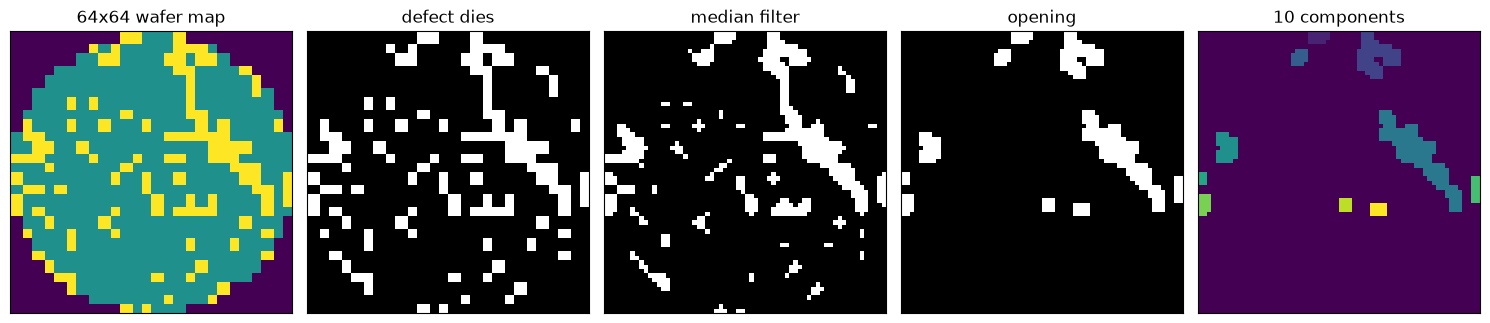

{'defect_ratio': np.float32(0.216), 'ring0': np.float32(0.234), 'ring1': np.float32(0.178), 'ring2': np.float32(0.212), 'ring3': np.float32(0.18), 'ring4': np.float32(0.256), 'sector0': np.float32(0.253), 'sector1': np.float32(0.176), 'sector2': np.float32(0.325), 'sector3': np.float32(0.192), 'sector4': np.float32(0.306), 'sector5': np.float32(0.141), 'sector6': np.float32(0.101), 'sector7': np.float32(0.292), 'n_comp': np.float32(10.0), 'largest_area': np.float32(0.043), 'second_area': np.float32(0.021), 'largest_r': np.float32(0.58), 'largest_elong': np.float32(4.209), 'largest_extent': np.float32(0.316), 'clean_ratio': np.float32(0.098), 'edge_vs_center': np.float32(0.022)}


In [10]:
ex = np.flatnonzero((y == CLASSES.index("Scratch")) & is_train)[3]
m = maps[ex]
defect = (m == 2).astype(np.uint8) * 255
blur = cv2.medianBlur(defect, 3)
opened = cv2.morphologyEx(blur, cv2.MORPH_OPEN, np.ones((3, 3), np.uint8))
n, lab, stats, _ = cv2.connectedComponentsWithStats((opened > 0).astype(np.uint8), connectivity=8)
steps = [("64x64 wafer map", m), ("defect dies", defect), ("median filter", blur), ("opening", opened),
         (f"{n - 1} components", lab)]
fig, axes = plt.subplots(1, 5, figsize=(15, 3.4))
for ax, (t, im) in zip(axes, steps):
    ax.imshow(im, cmap="viridis" if t.startswith("64") or t.endswith("components") else "gray", interpolation="nearest")
    ax.set_title(t); ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout()
plt.savefig("results/11_opencv_steps.png", dpi=110)
plt.show()
print(dict(zip(FEATURE_NAMES, handcrafted_features(m).round(3))))

In [11]:
t0 = time.perf_counter()
F = np.stack([handcrafted_features(mm) for mm in maps])
feat_sec = time.perf_counter() - t0
print(f"특징 추출 {feat_sec:.1f}초 ({len(maps):,}장) | {F.shape}")

특징 추출 100.6초 (172,950장) | (172950, 22)


In [12]:
baselines = {}
majority = np.full(is_test.sum(), CLASSES.index("none"))
baselines["다수 클래스(none)"] = classification_report_dict(y[is_test], majority)

for name, cw in [("OpenCV 특징 + RF", None), ("OpenCV 특징 + RF (균형 가중치)", "balanced_subsample")]:
    rf = RandomForestClassifier(500, min_samples_leaf=2, class_weight=cw, n_jobs=-1, random_state=SEED)
    t0 = time.perf_counter()
    rf.fit(F[tr], y[tr])
    fit_sec = time.perf_counter() - t0
    t0 = time.perf_counter()
    pred = rf.predict(F[is_test])
    pred_sec = time.perf_counter() - t0
    rep = classification_report_dict(y[is_test], pred)
    rep["val_macro_f1"] = classification_report_dict(y[va], rf.predict(F[va]))["macro_f1"]
    rep["test_nodup_macro_f1"] = classification_report_dict(y[is_test & ~dup_test],
                                                            rf.predict(F[is_test & ~dup_test]))["macro_f1"]
    rep.update(fit_sec=round(fit_sec, 1), predict_sec=round(pred_sec, 2))
    baselines[name] = rep
    if cw is None:
        imp = pd.Series(rf.feature_importances_, index=FEATURE_NAMES).sort_values(ascending=False)
        np.save("results/11_rf_test_pred.npy", pred)

for k, v in baselines.items():
    print(f"{k:28s} 검증 macroF1 {v.get('val_macro_f1', float('nan')):.3f} | 평가 macroF1 {v['macro_f1']:.3f} "
          f"| accuracy {v['accuracy']:.3f}")
print(imp.head(8).round(3))

다수 클래스(none)                 검증 macroF1 nan | 평가 macroF1 0.107 | accuracy 0.933
OpenCV 특징 + RF               검증 macroF1 0.574 | 평가 macroF1 0.569 | accuracy 0.933
OpenCV 특징 + RF (균형 가중치)      검증 macroF1 0.539 | 평가 macroF1 0.575 | accuracy 0.930
edge_vs_center    0.161
largest_area      0.127
ring0             0.080
ring4             0.077
largest_elong     0.073
ring3             0.069
largest_r         0.068
ring2             0.054
dtype: float64


In [13]:
pc = pd.DataFrame({k: {c: v["per_class"][c]["f1"] for c in CLASSES} for k, v in baselines.items()})
print(pc)

           다수 클래스(none)  OpenCV 특징 + RF  OpenCV 특징 + RF (균형 가중치)
Center            0.000           0.352                    0.404
Donut             0.000           0.624                    0.621
Edge-Loc          0.000           0.538                    0.523
Edge-Ring         0.000           0.506                    0.495
Loc               0.000           0.454                    0.433
Near-full         0.000           0.968                    0.974
Random            0.000           0.691                    0.709
Scratch           0.000           0.019                    0.052
none              0.966           0.968                    0.967


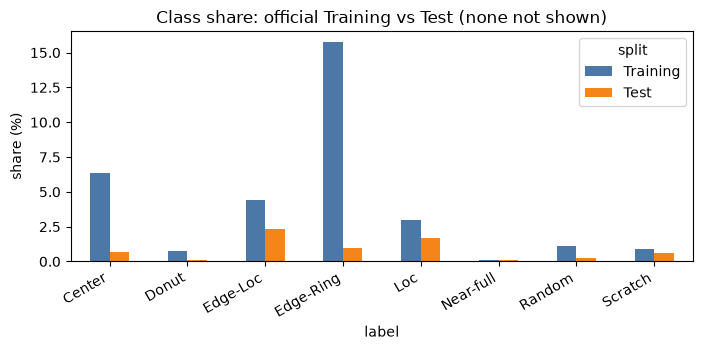

In [14]:
fig, ax = plt.subplots(figsize=(7, 3.6))
ct_pct[["Training", "Test"]].drop(index="none").plot.bar(ax=ax, color=["#4C78A8", "#F58518"])
ax.set_ylabel("share (%)"); ax.set_title("Class share: official Training vs Test (none not shown)")
plt.xticks(rotation=30, ha="right"); plt.tight_layout()
plt.savefig("results/11_split_distribution.png", dpi=110)
plt.show()

In [15]:
out = {
    "env": ENV,
    "n_raw": int(len(labeled) + 0),
    "class_counts": counts.reindex(CLASSES).astype(int).to_dict(),
    "split_counts": {s: ct[s].astype(int).to_dict() for s in ct.columns},
    "split_pct": {s: ct_pct[s].to_dict() for s in ct_pct.columns},
    "n_shapes": int(shapes.nunique()),
    "size_by_class": size_by_class.to_dict("index"),
    "dev": {"train": int(tr.sum()), "val": int(va.sum()), "test": int(is_test.sum()),
            "val_lot_start": int(D["lot_num"][va].min())},
    "dup_test": int(dup_test.sum()),
    "conflict_labels": int((g > 1).sum()),
    "shortcut_size_only": {k: {"accuracy": v["accuracy"], "macro_f1": v["macro_f1"]} for k, v in shortcut.items()},
    "feature_sec": round(feat_sec, 1),
    "baselines": baselines,
    "rf_importance_top": imp.head(10).round(4).to_dict(),
}
Path("results/11_eda_opencv.json").write_text(json.dumps(out, ensure_ascii=False, indent=2), encoding="utf-8")
np.save("results/11_handcrafted_features.npy", F)